## LangGraph 오케스트레이션 패턴 4가지

**오케스트레이션(Orchestration)** 은 여러 노드 또는 에이전트의 실행 순서, 분기, 병렬 처리, 반복, 협업 방식을 제어하는 기술입니다.

LangGraph에서는 주로 StateGraph, add_edge(), add_conditional_edges() 등으로 구현합니다.

> **한눈에 보기**
> - 오케스트레이션 패턴 4가지: ① 순차형 ② 슈퍼바이저형 ③ 피드백 루프형 ④ 계층형(서브그래프 + wrapper). 다른 것은 "다음 순서를 누가 정하나"뿐
> - 보너스: `create_agent` 전문가 에이전트를 통역사 함수로 감싸 LangGraph 노드로 (주말 나들이 플래너: 날씨 → 장소 → 예산, 초과면 되돌리기)
> - LangSmith: 환경변수 3개로 실행 기록(트레이스) 켜기, `tracing_context(enabled=False)`로 잠시 끄기
> - 정리 문서: [오케스트레이션패턴과LangSmith.md](오케스트레이션패턴과LangSmith.md) · 강의 슬라이드 이미지 포함, 📝 정리 셀은 직접 정리

대표적인 오케스트레이션 패턴 6가지
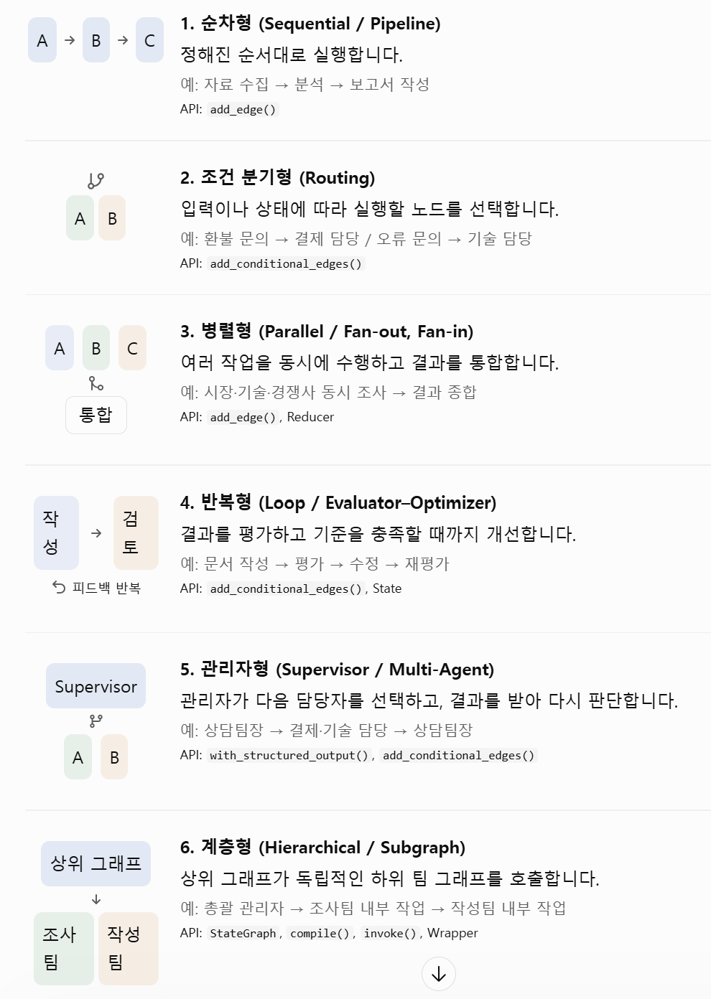


| 패턴 | 지휘 방식 | 비유 | 예제 |
|---|---|---|---|
| ① **순차형** | 정해진 순서대로 차례차례 | 공장 생산 라인 | 블로그 글 제작 라인 |
| ② **슈퍼바이저형** | 관리자 한 명이 다음 담당자를 지목 | 상담 센터 팀장 | 고객 문의 센터 |
| ③ **협업·피드백 루프형** | 두 에이전트가 주고받으며 품질을 올림 | 작가와 편집자 | 홍보 문구 다듬기 |
| ④ **계층형** | 총괄 관리자 → 팀장 → 팀원 | 회사 조직도 | 교육과정 기획서 |

각 예제 마지막에는 **노드 워크플로우를 그림으로 출력**합니다.

### LangChain과 LangGraph — 누가 무엇을 하나?

모든 코드에는 주석으로 **`[LangChain]`** 또는 **`[LangGraph]`** 표시를 붙였습니다. 두 라이브러리가 맡는 일을 구분하며 읽어 보세요.

| | LangChain | LangGraph |
|---|---|---|
| 한 줄 역할 | **에이전트 한 명이 일을 잘하게** | **여러 에이전트가 함께 일하게** |
| 비유 | 연주자의 **악기와 연주 실력** | 오케스트라의 **지휘와 악보** |
| 이 노트북에서 쓰는 기능 | `ChatOpenAI`, `ChatGoogleGenerativeAI` (모델 호출)<br>`SystemMessage`, `HumanMessage` (메시지)<br>`with_structured_output` (정해진 형식으로 답 받기) | `StateGraph` (작업 흐름도)<br>`State` (공유 메모장)<br>`add_node` / `add_edge` (작업과 순서)<br>`add_conditional_edges` (분기·반복)<br>서브그래프 (팀 단위 묶기) |

<br>

> 💡 **오케스트레이션은 LangGraph의 일**입니다. 각 노드 안에서 LLM을 부르는 일은 LangChain이 하고, 그 노드들을 어떤 순서·조건으로 이을지는 LangGraph가 정합니다.

---
### 0. 환경 준비

**Python 3.12** 기준, 2026년 10월 최신 버전으로...

In [1]:
# %pip install -q -U langchain  langchain-core   langgraph   langchain-openai   langchain-google-genai   

API 키는 환경변수(`setx`) 또는 `.env` 파일로 준비합니다.
```
OPENAI_API_KEY=sk-...
GEMINI_API_KEY=AIza...      (GOOGLE_API_KEY 이름도 가능)
```

In [2]:
import os
#from dotenv import load_dotenv

#load_dotenv()          # .env 파일이 있으면 읽고, 없으면 환경변수를 그대로 사용

print("OPENAI_API_KEY :", "✅" if os.getenv("OPENAI_API_KEY") else "❌")
print("GEMINI_API_KEY :", "✅" if (os.getenv("GEMINI_API_KEY") or os.getenv("GOOGLE_API_KEY")) else "❌")

OPENAI_API_KEY : ✅
GEMINI_API_KEY : ✅


#### 공통 준비: 모델, LLM 호출 함수, 그래프 그리기 함수

| 모델 | 맡는 역할 |
|---|---|
| `gpt-4o-mini` | 판단·분류·채점처럼 **형식이 정확해야 하는 일** (관리자, 검토자) |
| `gemini-3.5-flash-lite` | 글쓰기처럼 **생성량이 많은 일** (작성자) |

In [3]:
import logging
from IPython.display import Image, display

from langchain_openai import ChatOpenAI                          # [LangChain] OpenAI 모델
from langchain_google_genai import ChatGoogleGenerativeAI        # [LangChain] Gemini 모델
from langchain_core.messages import SystemMessage, HumanMessage  # [LangChain] 메시지

logging.getLogger("google_genai.models").setLevel(logging.ERROR)  # Gemini SDK 의 안내성 경고 숨기기

gpt = ChatOpenAI(model="gpt-4o-mini", temperature=0)            # [LangChain]
gemini = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")   # [LangChain] 샘플링 값이 고정된 모델이라 temperature 를 주지 않음


def ask(model, system: str, user: str) -> str:
    # [LangChain] 역할(system)과 요청(user)을 주고 답변 텍스트만 받는다
    return model.invoke([SystemMessage(system), HumanMessage(user)]).text


def show_graph(app, xray: bool = False):
    # [LangGraph] 컴파일된 그래프를 그림으로 출력 (인터넷이 막혀 있으면 Mermaid 텍스트로 출력)
    try:
        display(Image(app.get_graph(xray=xray).draw_mermaid_png()))
    except Exception as e:
        print(f"[그림 출력 실패 → Mermaid 텍스트] {e}\n")
        print(app.get_graph(xray=xray).draw_mermaid())


print("gpt    :", ask(gpt, "한 단어로 답해라.", "인사해줘"))
print("gemini :", ask(gemini, "한 단어로 답해라.", "인사해줘"))

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


gpt    : 안녕하세요!
gemini : 안녕하세요.


#### LangGraph 그래프를 만드는 4단계 (모든 패턴 공통)

```python
class MyState(TypedDict): ...          # ① State   : 에이전트들이 함께 쓰는 '공유 메모장'
def my_node(state): return {...}       # ② Node    : 일을 하는 함수. 바꾼 메모만 돌려준다
builder.add_edge("a", "b")             # ③ Edge    : 일의 순서 (조건부 엣지는 분기·반복)
app = builder.compile()                # ④ Compile : 실행 가능한 앱으로 만들기
```
네 가지 패턴은 모두 이 구조이고, **③ 엣지를 어떻게 연결하느냐**만 다릅니다. 이것이 곧 오케스트레이션입니다.

---
### ① 순차형 (Sequential) — 정해진 순서대로

#### 개념
에이전트가 **미리 정한 순서대로** 한 명씩 일하고, 앞 사람의 결과를 다음 사람이 이어받습니다.

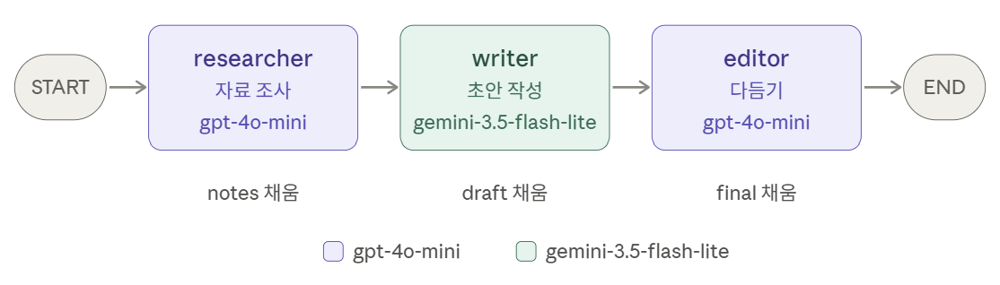

### 오케스트레이션의 역할
**순서를 고정**하는 것뿐입니다. 누가 다음에 일할지 판단하는 LLM이 없고, `add_edge`로 그은 선이 곧 지휘입니다.

| 장점 | 단점 | 언제 쓰나 |
|---|---|---|
| 가장 단순하고 예측 가능, 디버깅 쉬움 | 상황에 따라 순서를 바꿀 수 없음 | 단계가 항상 같은 업무 (보고서 작성, 데이터 처리 파이프라인) |

In [4]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END     # [LangGraph]


# ① State — 공유 메모장: 각 에이전트가 자기 칸을 채운다
class BlogState(TypedDict):
    topic: str       # 주제 (입력)
    notes: str       # researcher 가 채움
    draft: str       # writer 가 채움
    final: str       # editor 가 채움


# ② Node — 각 에이전트 (노드 안의 LLM 호출은 LangChain 의 일)
def researcher(state: BlogState) -> dict:
    notes = ask(gpt, "너는 리서처다. 주제의 핵심 사실 3가지를 한국어 bullet 로만 써라.", state["topic"])   # [LangChain]
    print("🔎 researcher : 자료 조사 완료")
    return {"notes": notes}                            # 바꾼 칸만 돌려준다


def writer(state: BlogState) -> dict:
    draft = ask(gemini, "너는 IT 블로거다. 자료만 근거로 5문장 이내의 블로그 글을 써라.", state["notes"])   # [LangChain]
    print("✍️ writer     : 초안 작성 완료")
    return {"draft": draft}


def editor(state: BlogState) -> dict:
    final = ask(gpt, "너는 편집자다. 맞춤법을 고치고 첫 줄에 제목을 붙여라. 내용은 바꾸지 마라.", state["draft"])   # [LangChain]
    print("📝 editor     : 다듬기 완료")
    return {"final": final}


# ③ Edge — 순서를 고정하는 것이 순차형 오케스트레이션의 전부
builder = StateGraph(BlogState)                        # [LangGraph]
builder.add_node("researcher", researcher)             # [LangGraph]
builder.add_node("writer", writer)
builder.add_node("editor", editor)

builder.add_edge(START, "researcher")                  # [LangGraph] 순서: START → researcher
builder.add_edge("researcher", "writer")               #            → writer
builder.add_edge("writer", "editor")                   #            → editor
builder.add_edge("editor", END)                        #            → END

# ④ Compile
sequential_app = builder.compile()                     # [LangGraph]

In [5]:
result = sequential_app.invoke({"topic": "LangGraph로 멀티 에이전트를 만드는 이유"})

print("\n===== 최종 글 =====")
print(result["final"])

🔎 researcher : 자료 조사 완료
✍️ writer     : 초안 작성 완료
📝 editor     : 다듬기 완료

===== 최종 글 =====
**LangGraph: 멀티 에이전트 소통과 협업의 강력한 도구**

LangGraph는 자연어 처리와 그래프 기반 데이터 구조를 결합해 멀티 에이전트 간의 효과적인 소통과 협업을 지원하는 강력한 도구입니다. 이 시스템을 활용하면 정보의 구조화와 관계가 명확해져 에이전트 간의 상호작용이 극대화됩니다. 또한, 다양한 도메인에서 지식 표현과 추론을 돕기 때문에 에이전트들이 복잡한 문제를 해결하는 데 필요한 정보를 효율적으로 공유할 수 있습니다. 복잡한 멀티 에이전트 환경을 구축하고자 한다면 LangGraph가 최적의 선택이 될 것입니다.


**📝 정리** — 최종 글이 "LangGraph는 **자연어 처리와 그래프 기반 데이터 구조를 결합**"한다고 시작한다. 10/23에 본 것과 같은 틀린 설명. 리서처에게 자료를 주지 않으면 세 단계를 거쳐도 틀린 내용이 다듬어질 뿐이다.

> 💡 **확인 포인트**: 출력 순서가 항상 `researcher → writer → editor`입니다. 몇 번을 실행해도 바뀌지 않아요. 이것이 순차형의 장점이자 한계입니다.

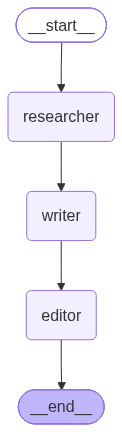

In [6]:
show_graph(sequential_app)

---
### ② 슈퍼바이저형 (Supervisor) — 관리자가 다음 담당자를 지목

#### 개념
**슈퍼바이저(관리자) 에이전트**가 요청을 보고 "이번엔 누가 일할지"를 정합니다. 담당자는 일을 마치면 **항상 관리자에게 돌아와** 보고하고, 관리자는 할 일이 남았는지 다시 판단합니다.

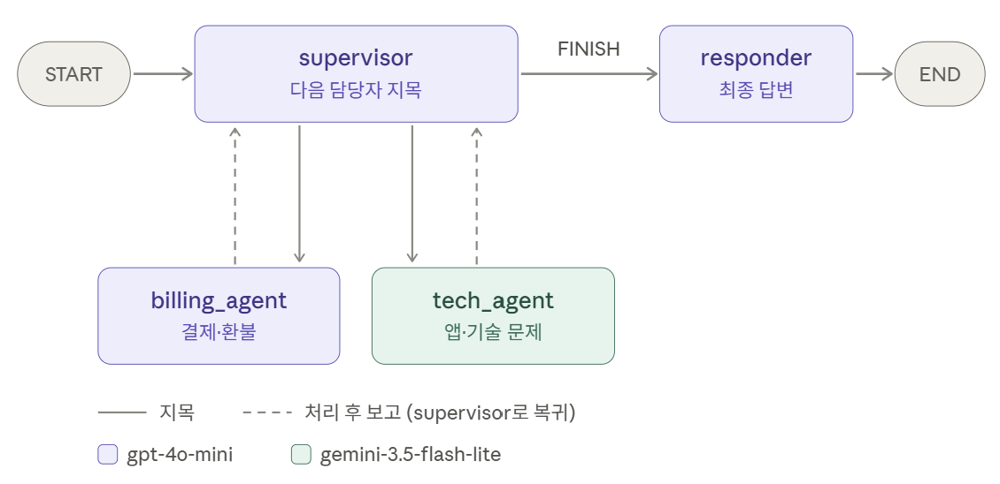

#### 오케스트레이션의 역할
**LLM(슈퍼바이저)이 실행 중에 순서를 결정**합니다. LangGraph는 슈퍼바이저의 결정(`next`)을 읽어 그 노드로 보내는 길(조건부 엣지)을 제공합니다.

| 장점 | 단점 | 언제 쓰나 |
|---|---|---|
| 요청에 따라 필요한 담당자만, 필요한 순서로 | 관리자 LLM 호출이 늘어남, 판단이 틀릴 수 있음 | 요청 유형이 다양한 업무 (상담, 업무 분배) |

In [7]:
import operator
from typing import Annotated, Literal
from pydantic import BaseModel, Field


class SupportState(TypedDict):
    request: str                                  # 고객 문의
    reports: Annotated[list[str], operator.add]   # 담당자 보고서 — 리듀서(operator.add)로 '이어 붙이기'
    next: str                                     # 슈퍼바이저가 지목한 다음 담당자
    steps: int                                    # 슈퍼바이저 판단 횟수 (무한 반복 방지)
    answer: str                                   # 최종 답변


# [LangChain] 슈퍼바이저가 반드시 이 형식으로 답하게 한다 (구조화 출력)
class Route(BaseModel):
    next: Literal["billing_agent", "tech_agent", "FINISH"] = Field(description="다음 담당자. 모두 처리했으면 FINISH")
    reason: str = Field(description="그렇게 판단한 이유 한 문장")


supervisor_llm = gpt.with_structured_output(Route)       # [LangChain]
MAX_STEPS = 5


def supervisor(state: SupportState) -> dict:
    steps = state.get("steps", 0) + 1
    if steps > MAX_STEPS:                                # 안전장치
        return {"next": "FINISH", "steps": steps}

    done = "\n".join(state.get("reports", [])) or "(아직 없음)"
    route = supervisor_llm.invoke([                       # [LangChain]
        SystemMessage("너는 상담 센터 팀장이다. 담당자: billing_agent(결제·환불), tech_agent(앱·기술 문제).\n"
                      "문의에서 아직 처리되지 않은 부분이 있으면 담당자를 한 명 지목하고, 모두 처리됐으면 FINISH."),
        HumanMessage(f"문의: {state['request']}\n\n지금까지의 보고:\n{done}"),
    ])
    print(f"🧭 supervisor #{steps} → {route.next}  ({route.reason})")
    return {"next": route.next, "steps": steps}


def billing_agent(state: SupportState) -> dict:
    policy = "환불 규정: 구매 후 7일 이내 미사용이면 전액 환불, 단순 변심은 배송비 6,000원 고객 부담."
    report = ask(gpt, f"너는 결제·환불 담당이다. 아래 규정만 근거로 두 문장으로 답해라.\n{policy}", state["request"])
    print("   💳 billing_agent : 처리 완료")
    return {"reports": [f"[결제 담당] {report}"]}


def tech_agent(state: SupportState) -> dict:
    report = ask(gemini, "너는 앱 기술 지원 담당이다. 고객이 따라 할 해결 단계를 3단계 이내로 안내해라.", state["request"])
    print("   🛠️ tech_agent    : 처리 완료")
    return {"reports": [f"[기술 담당] {report}"]}


def responder(state: SupportState) -> dict:
    answer = ask(gpt, "너는 상담원이다. 담당자 보고를 합쳐 고객에게 보낼 정중한 답변 하나로 정리해라.",
                 "\n\n".join(state["reports"]))
    print("💬 responder : 최종 답변 작성")
    return {"answer": answer}


# [LangGraph] 슈퍼바이저의 결정(next)을 읽어 다음 노드 이름을 돌려주는 '길 안내' 함수
def route_from_supervisor(state: SupportState) -> str:
    return "responder" if state["next"] == "FINISH" else state["next"]


builder = StateGraph(SupportState)                                   # [LangGraph]
builder.add_node("supervisor", supervisor)
builder.add_node("billing_agent", billing_agent)
builder.add_node("tech_agent", tech_agent)
builder.add_node("responder", responder)

builder.add_edge(START, "supervisor")
builder.add_conditional_edges("supervisor", route_from_supervisor,  # [LangGraph] 실행 중에 갈 곳이 정해짐
                              ["billing_agent", "tech_agent", "responder"])
builder.add_edge("billing_agent", "supervisor")                      # [LangGraph] 일을 마치면 항상 관리자에게 복귀
builder.add_edge("tech_agent", "supervisor")
builder.add_edge("responder", END)

supervisor_app = builder.compile()

In [8]:
# 한 가지 문제만 있는 문의 → 필요한 담당자만 부르는지 확인
result = supervisor_app.invoke({ "request": "어제 산 이어폰 환불받고 싶어요. ",  "steps": 0 })
print("\n===== 고객에게 보낼 답변 =====")
print(result["answer"])

🧭 supervisor #1 → billing_agent  (환불 요청이므로 결제·환불 담당자에게 전달해야 합니다.)
   💳 billing_agent : 처리 완료
🧭 supervisor #2 → billing_agent  (환불 요청이므로 결제 담당자가 필요합니다.)
   💳 billing_agent : 처리 완료
🧭 supervisor #3 → billing_agent  (환불 요청에 대한 처리가 필요합니다.)
   💳 billing_agent : 처리 완료
🧭 supervisor #4 → billing_agent  (환불 요청에 대한 추가 처리가 필요합니다.)
   💳 billing_agent : 처리 완료
🧭 supervisor #5 → billing_agent  (환불 요청이 있으나, 결제 담당자의 추가 확인이 필요합니다.)
   💳 billing_agent : 처리 완료
💬 responder : 최종 답변 작성

===== 고객에게 보낼 답변 =====
안녕하세요, 고객님.

저희 제품에 대한 관심과 구매에 감사드립니다. 구매 후 7일 이내에 미사용 상태라면 전액 환불이 가능하다는 점을 안내드립니다. 다만, 단순 변심으로 인한 환불 요청 시에는 배송비 6,000원이 고객님 부담으로 발생하게 됩니다.

추가적인 문의사항이 있으시면 언제든지 연락 주시기 바랍니다. 감사합니다.

좋은 하루 되세요!


**📝 정리** — 슈퍼바이저가 billing_agent를 **5번 연속** 지목하고 FINISH를 고르지 않았다. `MAX_STEPS=5` 안전장치 덕분에 끝났고, 담당자 호출 4번은 낭비였다.

In [9]:
# 한 가지 문제만 있는 문의 → 필요한 담당자만 부르는지 확인
result = supervisor_app.invoke({"request": "앱을 켜면 화면이 하얗게 멈춰요.", "steps": 0})
print("\n===== 고객에게 보낼 답변 =====")
print(result["answer"])

🧭 supervisor #1 → tech_agent  (앱의 기술 문제로 인해 화면이 하얗게 멈추는 현상이 발생하고 있습니다.)
   🛠️ tech_agent    : 처리 완료
🧭 supervisor #2 → tech_agent  (앱 문제 해결을 위한 추가 정보 요청이 필요합니다.)
   🛠️ tech_agent    : 처리 완료
🧭 supervisor #3 → tech_agent  (앱이 하얗게 멈추는 문제에 대한 추가 지원이 필요합니다.)
   🛠️ tech_agent    : 처리 완료
🧭 supervisor #4 → tech_agent  (앱이 멈추는 현상에 대한 추가 지원이 필요합니다.)
   🛠️ tech_agent    : 처리 완료
🧭 supervisor #5 → tech_agent  (앱이 멈추는 현상에 대한 추가 지원이 필요합니다.)
   🛠️ tech_agent    : 처리 완료
💬 responder : 최종 답변 작성

===== 고객에게 보낼 답변 =====
안녕하세요, 고객님.

앱 사용 중 불편을 드려 진심으로 사과드립니다. 문제 해결을 위해 아래의 3단계를 순서대로 진행해 주시기 바랍니다.

1. **앱 강제 종료**: 스마트폰의 최근 앱 화면에서 해당 앱을 위로 밀어 완전히 종료해 주세요.
2. **기기 재부팅**: 스마트폰을 껐다가 다시 켜 주세요.
3. **앱 재설치**: 앱을 삭제한 후, 앱스토어(또는 플레이스토어)에서 최신 버전으로 다시 다운로드해 주세요.

위 방법으로도 문제가 해결되지 않는 경우, 사용 중이신 스마트폰 기종을 알려주시면 추가로 도와드리겠습니다.

감사합니다.


**📝 정리** — 기술 문의도 tech_agent를 5번 연속 지목. 같은 문제가 반복된다.

In [10]:
# 두 가지 문제가 섞인 문의 → 슈퍼바이저가 두 담당자를 차례로 지목하는지 확인
result = supervisor_app.invoke({
    "request": "앱 로그인이 안 돼서 주문 내역도 못 봐요. 구매한 제품에 대한 환불도 받고싶어요",
    "steps": 0,
})
print("\n===== 고객에게 보낼 답변 =====")
print(result["answer"])

🧭 supervisor #1 → tech_agent  (앱 로그인 문제로 인해 주문 내역을 확인할 수 없으므로 기술 지원이 필요합니다.)
   🛠️ tech_agent    : 처리 완료
🧭 supervisor #2 → tech_agent  (로그인 문제 해결이 아직 완료되지 않았습니다.)
   🛠️ tech_agent    : 처리 완료
🧭 supervisor #3 → billing_agent  (환불 신청을 위해 고객센터에 연락이 필요합니다.)
   💳 billing_agent : 처리 완료
🧭 supervisor #4 → billing_agent  (환불 신청을 위해 결제 담당자의 추가 안내가 필요합니다.)
   💳 billing_agent : 처리 완료
🧭 supervisor #5 → tech_agent  (로그인 문제 해결이 아직 완료되지 않았습니다.)
   🛠️ tech_agent    : 처리 완료
💬 responder : 최종 답변 작성

===== 고객에게 보낼 답변 =====
안녕하세요, 고객님.

먼저, 로그인 문제와 환불 요청으로 불편을 드려 진심으로 사과드립니다. 아래의 단계를 따라 주시면 문제를 신속하게 해결할 수 있도록 도와드리겠습니다.

**1단계: 로그인 문제 해결**
- 앱을 완전히 종료한 후 재실행해 주세요. 
- 문제가 지속될 경우, 스마트폰 설정에서 **[앱] > [해당 앱] > [저장공간]**으로 이동하여 **'캐시 삭제'**를 진행해 주시고, 그래도 문제가 해결되지 않으면 앱을 삭제 후 최신 버전으로 재설치해 주세요.

**2단계: 주문 내역 확인 및 환불 신청**
- 로그인이 정상화되면 **[마이페이지 > 주문/배송 내역]**에서 구매하신 제품을 확인하실 수 있습니다. 
- 환불을 원하시는 상품을 선택하여 직접 환불을 신청해 주세요. 구매 후 7일 이내 미사용 제품에 한해 전액 환불이 가능하며, 단순 변심으로 인한 환불은 배송비 6,000원이 고객님 부담임을 안내드립니다.

**3단계: 고객센터 1:1 문의**
- 만

**📝 정리** — 섞인 문의는 tech → tech → billing → billing → tech로 상한까지. 세 번 모두 FINISH 없음. 완료 여부는 코드가 처리한 항목을 표시해 넘기는 편이 안전하다.

> 💡 **확인 포인트**: 두 문의의 실행 순서가 **다릅니다.** 같은 그래프인데도 슈퍼바이저 LLM의 판단에 따라 길이 바뀌죠. 순차형과의 가장 큰 차이입니다.
>
> 📌 `operator.add` 리듀서 덕분에 담당자들의 보고가 **덮어써지지 않고 이어 붙여집니다.**
>
> 📌 `route_from_supervisor` 함수 대신 노드가 `Command(goto=...)`를 반환해 직접 이동할 곳을 정하는 방법도 있습니다 (exam13 예제 ③).

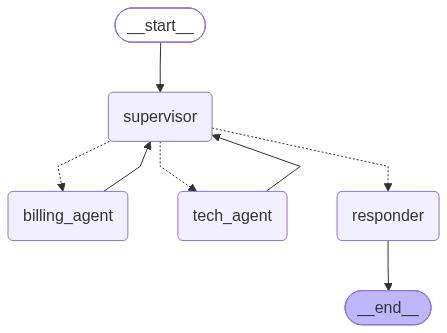

In [11]:
show_graph(supervisor_app)

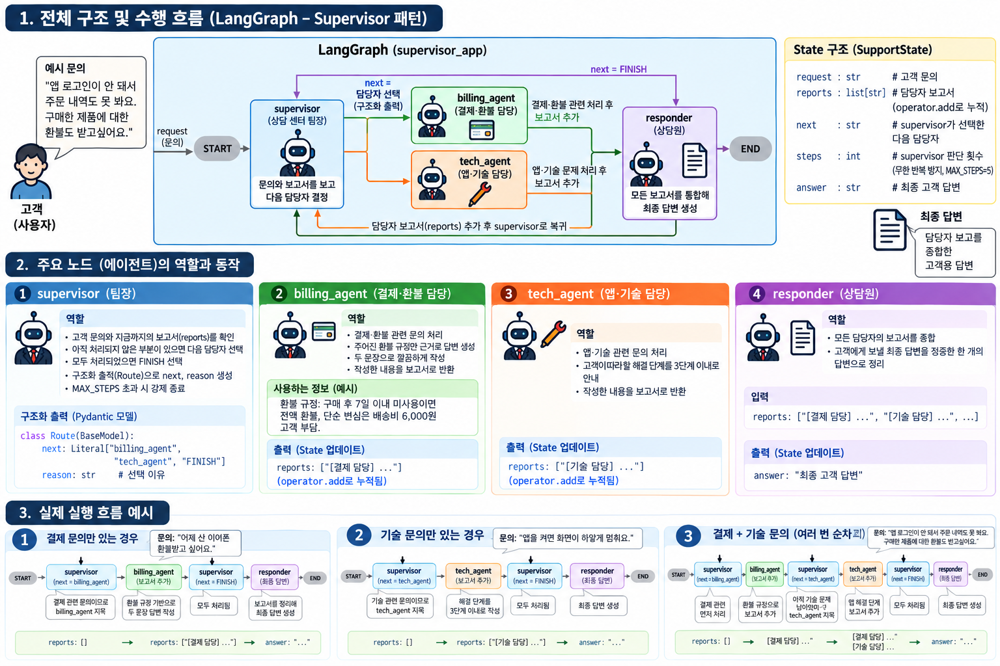

---
### ③ 상호 협업 및 피드백 루프형 (Collaboration & Feedback Loop)

#### 개념
두 에이전트가 **결과를 주고받으며 품질을 올립니다.** 작성자가 쓰면 검토자가 점수와 피드백을 주고, 기준에 못 미치면 작성자가 피드백을 반영해 다시 씁니다.

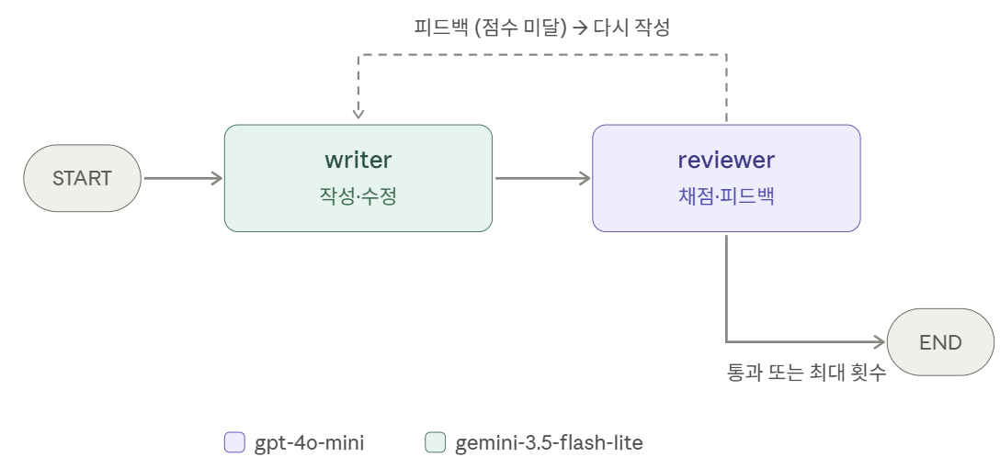

#### 오케스트레이션의 역할
**반복(루프)과 종료 조건**을 관리합니다. LangGraph의 조건부 엣지가 "다시 writer로 / END로"를 정하고, **최대 반복 횟수**로 무한 루프를 막습니다.

| 장점 | 단점 | 언제 쓰나 |
|---|---|---|
| 스스로 품질을 끌어올림 | 반복할수록 시간·비용 증가 | 품질 기준이 분명한 결과물 (글, 코드, 번역) |

<br>

> 💡 작성자(gemini)와 검토자(gpt)에서 **서로 다른 모델**을 쓰면, 같은 모델이 자기 글에 관대해지는 문제를 줄일 수 있습니다.

In [12]:
PASS_SCORE = 8       # 통과 점수
MAX_ROUNDS = 3       # 최대 작성 횟수


class LoopState(TypedDict):
    topic: str
    draft: str
    score: int
    feedback: str
    round: int


class Review(BaseModel):                                  # [LangChain] 검토 결과 형식
    score: int = Field(ge=1, le=10, description="10점 만점 점수")
    feedback: str = Field(description="구체적인 개선점 1~2개. 통과 수준이면 '없음'")


reviewer_llm = gpt.with_structured_output(Review)        # [LangChain]


def loop_writer(state: LoopState) -> dict:
    rnd = state.get("round", 0) + 1
    if state.get("feedback"):          # 2회차부터: 피드백을 반영해 수정
        prompt = f"이전 문구:\n{state['draft']}\n\n피드백:\n{state['feedback']}\n\n피드백을 반영해 다시 써라."
    else:                              # 1회차: 처음 작성
        prompt = f"주제: {state['topic']}\n이 주제의 홍보 문구를 3문장 이내로 써라."
    draft = ask(gemini, "너는 카피라이터다. 과장 없이 구체적인 혜택이 드러나게 써라.", prompt)   # [LangChain]
    print(f"✍️ writer   : {rnd}회차 작성")
    return {"draft": draft, "round": rnd}


def reviewer(state: LoopState) -> dict:
    r = reviewer_llm.invoke([                              # [LangChain]
        SystemMessage("너는 깐깐한 마케팅 팀장이다. 명확성·구체성·간결성으로 엄격하게 채점해라."),
        HumanMessage(f"주제: {state['topic']}\n문구:\n{state['draft']}"),
    ])
    print(f"🧐 reviewer : {r.score}점 / {r.feedback}")
    return {"score": r.score, "feedback": r.feedback}


# [LangGraph] 루프를 이어갈지 끝낼지 정하는 함수 — 피드백 루프 오케스트레이션의 핵심
def continue_or_end(state: LoopState) -> str:
    if state["score"] >= PASS_SCORE:
        print("   ✅ 통과!")
        return END
    if state["round"] >= MAX_ROUNDS:
        print("   ⏹️ 최대 횟수 도달 — 종료")
        return END
    return "writer"                                        # 피드백을 들고 다시 작성자에게


builder = StateGraph(LoopState)                            # [LangGraph]
builder.add_node("writer", loop_writer)
builder.add_node("reviewer", reviewer)

builder.add_edge(START, "writer")
builder.add_edge("writer", "reviewer")
builder.add_conditional_edges("reviewer", continue_or_end, ["writer", END])   # [LangGraph] 루프 또는 종료

loop_app = builder.compile()

In [13]:
result = loop_app.invoke({"topic": "직장인을 위한 6시간 'AI 에이전트 입문' 주말 강좌"})

print(f"\n===== 최종 문구 ({result['round']}회차, {result['score']}점) =====")
print(result["draft"])

✍️ writer   : 1회차 작성
🧐 reviewer : 8점 / 문구가 명확하고 구체적이며 간결하지만, 강좌의 대상과 기대 효과를 좀 더 강조하면 좋겠습니다.
   ✅ 통과!

===== 최종 문구 (1회차, 8점) =====
반복되는 단순 업무를 줄여줄 AI 에이전트의 기본 개념과 실무 활용법을 단 6시간 만에 익힐 수 있습니다.
주말 하루 투자로 내 업무에 바로 적용 가능한 맞춤형 AI 자동화 워크플로우를 직접 만들어보세요.
강좌 수강생 전원에게 실습용 프롬프트 템플릿과 복습용 가이드북을 무료로 제공합니다.


**📝 정리** — 1회차에 8점으로 바로 통과. 점수에 따라 반복 횟수가 실행마다 달라진다.

> 💡 **확인 포인트**: 점수에 따라 반복 횟수가 실행마다 달라질 수 있습니다. `PASS_SCORE`를 9로 올리거나 `MAX_ROUNDS`를 바꿔 보며 루프가 어떻게 달라지는지 관찰해 보세요.
>
> ⚠️ 루프가 있는 그래프에는 **반드시 종료 조건과 최대 횟수**를 둡니다. 없으면 검토자가 계속 낮은 점수를 줄 때 끝나지 않습니다.

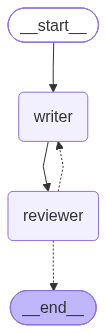

In [14]:
show_graph(loop_app)

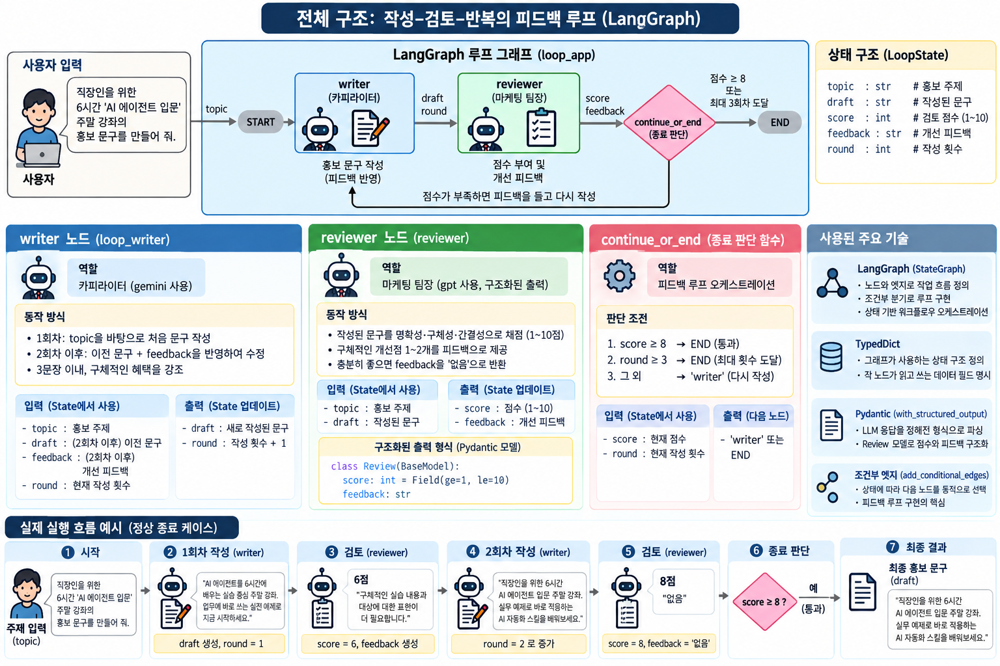

---
### ④ 계층형 (Hierarchical) — 총괄 관리자 → 팀장 → 팀원

#### 개념
에이전트가 많아지면 슈퍼바이저 한 명이 모두를 관리하기 어렵습니다. 그래서 **팀을 나누고, 팀마다 팀장을 두고, 그 위에 총괄 관리자**를 둡니다. 회사 조직도와 같아요.

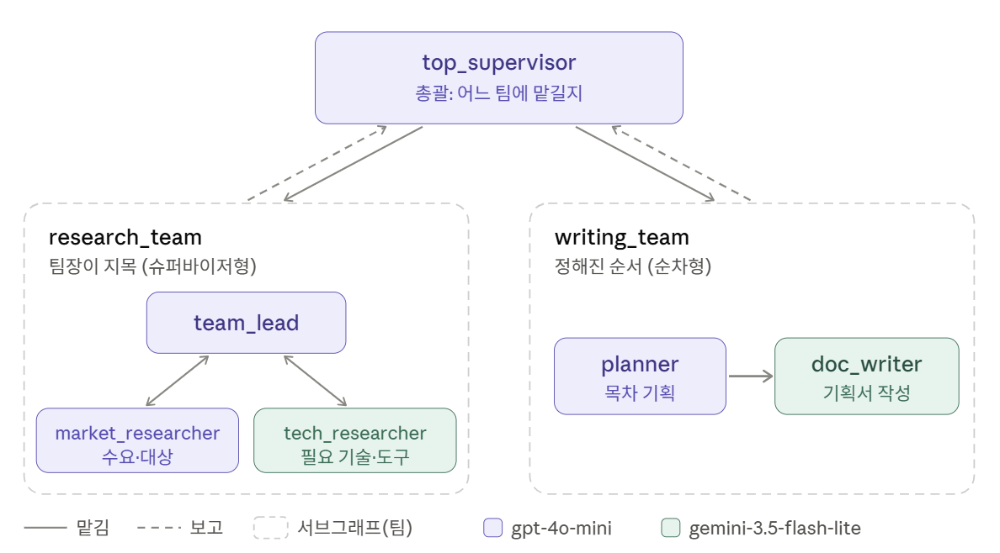

#### 오케스트레이션의 역할
**두 단계로 나뉩니다.**
- **총괄 관리자**는 팀 단위로만 판단합니다. 팀 안에서 누가 일하는지는 모릅니다.
- **각 팀**은 자기 방식으로 일합니다. 이 예제에서 조사팀은 **슈퍼바이저형**(팀장이 지목), 작성팀은 **순차형**입니다.

LangGraph에서는 **팀 하나를 독립된 그래프(서브그래프)로 만들고**, 그것을 상위 그래프의 노드 하나처럼 씁니다.

| 장점 | 단점 | 언제 쓰나 |
|---|---|---|
| 큰 시스템을 팀 단위로 나눠 관리, 팀별로 따로 개발·테스트 | 구조가 복잡, LLM 호출 많음 | 에이전트가 많고 업무 영역이 뚜렷이 나뉠 때 |

#### 4-1. 조사팀 서브그래프 — 팀 안은 슈퍼바이저형
팀장(`team_lead`)이 시장 조사원과 기술 조사원 중 필요한 사람을 지목합니다.

In [15]:
class ResearchState(TypedDict):
    task: str
    findings: Annotated[list[str], operator.add]   # 조사 결과를 이어 붙임
    next: str


class TeamRoute(BaseModel):                        # [LangChain]
    next: Literal["market_researcher", "tech_researcher", "DONE"] = Field(description="다음 조사원. 충분하면 DONE")


team_lead_llm = gpt.with_structured_output(TeamRoute)   # [LangChain]


def team_lead(state: ResearchState) -> dict:
    done = "\n".join(state.get("findings", [])) or "(없음)"
    if len(state.get("findings", [])) >= 2:              # 안전장치: 조사는 최대 2건
        return {"next": "DONE"}
    r = team_lead_llm.invoke([
        SystemMessage("너는 조사팀장이다. market_researcher(수요·대상), tech_researcher(필요 기술·도구) 중 "
                      "아직 조사하지 않은 쪽을 지목해라. 둘 다 끝났으면 DONE."),
        HumanMessage(f"과제: {state['task']}\n지금까지 조사:\n{done}"),
    ])
    print(f"      👔 [조사팀] team_lead → {r.next}")
    return {"next": r.next}


def market_researcher(state: ResearchState) -> dict:
    out = ask(gpt, "너는 시장 조사원이다. 수강 대상과 수요를 bullet 3개로 정리해라.", state["task"])
    print("      📊 [조사팀] market_researcher 완료")
    return {"findings": [f"[시장] {out}"]}


def tech_researcher(state: ResearchState) -> dict:
    out = ask(gemini, "너는 기술 조사원이다. 과정에 필요한 기술과 도구를 bullet 3개로 정리해라.", state["task"])
    print("      🧪 [조사팀] tech_researcher 완료")
    return {"findings": [f"[기술] {out}"]}


rb = StateGraph(ResearchState)                                  # [LangGraph] 팀 = 독립된 그래프
rb.add_node("team_lead", team_lead)
rb.add_node("market_researcher", market_researcher)
rb.add_node("tech_researcher", tech_researcher)

rb.add_edge(START, "team_lead")
rb.add_conditional_edges("team_lead", lambda s: END if s["next"] == "DONE" else s["next"],
                         ["market_researcher", "tech_researcher", END])
rb.add_edge("market_researcher", "team_lead")
rb.add_edge("tech_researcher", "team_lead")
research_team = rb.compile()

#### 4-2. 작성팀 서브그래프 — 팀 안은 순차형

In [16]:
class WritingState(TypedDict):
    task: str
    materials: str
    outline: str
    document: str


def planner(state: WritingState) -> dict:
    outline = ask(gpt, "너는 기획자다. 자료를 바탕으로 기획서 목차 4개를 번호 목록으로 써라.",
                  f"과제: {state['task']}\n자료:\n{state['materials']}")
    print("      🗂️ [작성팀] planner 완료")
    return {"outline": outline}


def doc_writer(state: WritingState) -> dict:
    doc = ask(gemini, "너는 문서 작성자다. 목차의 각 항목을 2문장씩 채워 짧은 기획서를 완성해라.",
              f"목차:\n{state['outline']}\n자료:\n{state['materials']}")
    print("      ✍️ [작성팀] doc_writer 완료")
    return {"document": doc}


wb = StateGraph(WritingState)                                   # [LangGraph]
wb.add_node("planner", planner)
wb.add_node("doc_writer", doc_writer)

wb.add_edge(START, "planner")
wb.add_edge("planner", "doc_writer")
wb.add_edge("doc_writer", END)
writing_team = wb.compile()

#### 4-3. 상위 그래프 — 총괄 관리자가 팀에 일을 맡김
팀(서브그래프)은 자기만의 State를 씁니다. 그래서 상위 그래프의 노드 함수가 **팀에게 일을 건네고(invoke), 결과만 받아** 상위 State에 적습니다. 회사에서 팀장에게 업무를 맡기고 보고서만 받는 것과 같아요.

In [17]:
class TopState(TypedDict):
    request: str
    research: str      # 조사팀 결과
    document: str      # 작성팀 결과
    next: str
    steps: int


class TopRoute(BaseModel):                                  # [LangChain]
    next: Literal["research_team", "writing_team", "FINISH"] = Field(description="다음에 일할 팀")
    reason: str = Field(description="이유 한 문장")


top_llm = gpt.with_structured_output(TopRoute)              # [LangChain]


def top_supervisor(state: TopState) -> dict:
    steps = state.get("steps", 0) + 1
    if steps > 4:                                            # 안전장치
        return {"next": "FINISH", "steps": steps}
    status = (f"조사 결과: {'있음' if state.get('research') else '없음'}\n"
              f"기획서: {'있음' if state.get('document') else '없음'}")
    r = top_llm.invoke([
        SystemMessage("너는 총괄 관리자다. 팀: research_team(자료 조사), writing_team(기획서 작성, 조사 결과가 필요).\n"
                      "진행 상황을 보고 다음 팀을 정해라. 기획서가 완성됐으면 FINISH."),
        HumanMessage(f"요청: {state['request']}\n진행 상황:\n{status}"),
    ])
    print(f"🏢 top_supervisor #{steps} → {r.next}  ({r.reason})")
    return {"next": r.next, "steps": steps}

# 상위 그래프와 하위 그래프 사이에서 데이터를 변환하고, 하위 그래프를 실행하는 연결자(Adapter) 역할
def call_research_team(state: TopState) -> dict:
    out = research_team.invoke({"task": state["request"], "findings": []})       # [LangGraph] 서브그래프 실행
    return {"research": "\n\n".join(out["findings"])}                           # 결과만 상위 State 에

# 상위 그래프와 하위 그래프 사이에서 데이터를 변환하고, 하위 그래프를 실행하는 연결자(Adapter) 역할
def call_writing_team(state: TopState) -> dict:
    out = writing_team.invoke({"task": state["request"], "materials": state.get("research", "")})
    return {"document": out["document"]}


tb = StateGraph(TopState)                                                    # [LangGraph]
tb.add_node("top_supervisor", top_supervisor)
tb.add_node("research_team", call_research_team)
tb.add_node("writing_team", call_writing_team)

tb.add_edge(START, "top_supervisor")
tb.add_conditional_edges("top_supervisor", lambda s: END if s["next"] == "FINISH" else s["next"],
                         ["research_team", "writing_team", END])
tb.add_edge("research_team", "top_supervisor")            # 팀 작업이 끝나면 총괄에게 보고
tb.add_edge("writing_team", "top_supervisor")
hierarchical_app = tb.compile()

In [18]:
result = hierarchical_app.invoke({"request": "직장인 대상 'AI 에이전트 입문' 6시간 교육과정 기획서를 만들어 줘", "steps": 0})

print("\n===== 조사 결과 =====")
print(result["research"])
print("\n===== 기획서 =====")
print(result["document"])

🏢 top_supervisor #1 → research_team  (기획서를 작성하기 위해서는 먼저 AI 에이전트에 대한 자료 조사가 필요합니다.)
      👔 [조사팀] team_lead → market_researcher
      📊 [조사팀] market_researcher 완료
      👔 [조사팀] team_lead → tech_researcher
      🧪 [조사팀] tech_researcher 완료
🏢 top_supervisor #2 → writing_team  (조사 결과가 이미 있으므로 기획서 작성을 위해 writing_team에 진행하도록 합니다.)
      🗂️ [작성팀] planner 완료
      ✍️ [작성팀] doc_writer 완료
🏢 top_supervisor #3 → FINISH  (기획서가 완성되었습니다.)

===== 조사 결과 =====
[시장] ### 'AI 에이전트 입문' 6시간 교육과정 기획서

#### 1. 교육 과정 개요
- **목표**: 직장인들이 AI 에이전트의 기본 개념과 활용 방법을 이해하고, 실무에 적용할 수 있는 기초 지식을 제공.
- **대상**: AI 및 기술에 대한 기초 지식이 없는 직장인, AI 도입을 고려하는 기업의 직원.
- **형태**: 이론 강의와 실습을 병행한 워크숍 형식.

#### 2. 교육 과정 구성
- **시간**: 총 6시간 (2시간 이론 + 4시간 실습)
- **주요 내용**:
  - **이론 (2시간)**:
    - AI 에이전트의 정의 및 역사
    - AI 에이전트의 작동 원리
    - 다양한 AI 에이전트의 사례 (챗봇, 가상 비서 등)
  - **실습 (4시간)**:
    - 간단한 AI 에이전트 구축 실습 (예: 챗봇 만들기)
    - AI 에이전트를 활용한 업무 자동화 사례 연구
    - 그룹 프로젝트: 팀별로 AI 에이전트를 활용한 아이디어 발표

#### 3. 교육 목표 및 기대 효과
- **AI 에이전트에 대한 이해 증진**: 참가자들이

**📝 정리** — 계층형 총괄은 "조사 결과 있음/없음, 기획서 있음/없음"처럼 짧은 상태를 받아 3번 만에 FINISH를 골랐다(슈퍼바이저형과 대조). 다만 시장 조사원의 결과가 시장 조사가 아니라 **교육과정 기획서 전체**였다. 역할 프롬프트가 짧으면 팀원이 최종 요청을 그대로 수행한다.

> 💡 **확인 포인트**: 출력의 들여쓰기를 보세요. `🏢 top_supervisor`는 팀 이름만 알고, 팀 안의 `👔 team_lead`·`📊 market_researcher` 같은 세부 진행은 **팀 내부에서만** 일어납니다. 이것이 계층형의 핵심인 **역할 분리**입니다.

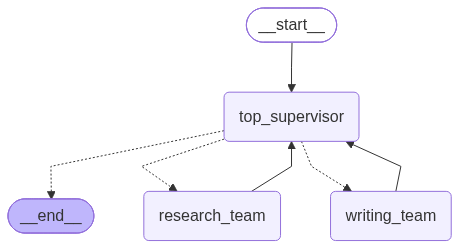

In [19]:
# 상위 그래프: 총괄 관리자와 두 팀 (팀 내부는 숨겨져 있음)
show_graph(hierarchical_app)

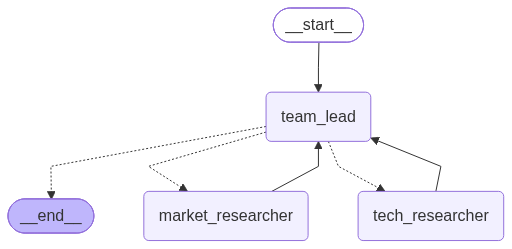

In [20]:
# 조사팀 내부 (팀 안의 슈퍼바이저형)
show_graph(research_team)

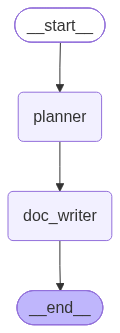

In [21]:
# 작성팀 내부 (팀 안의 순차형)
show_graph(writing_team)

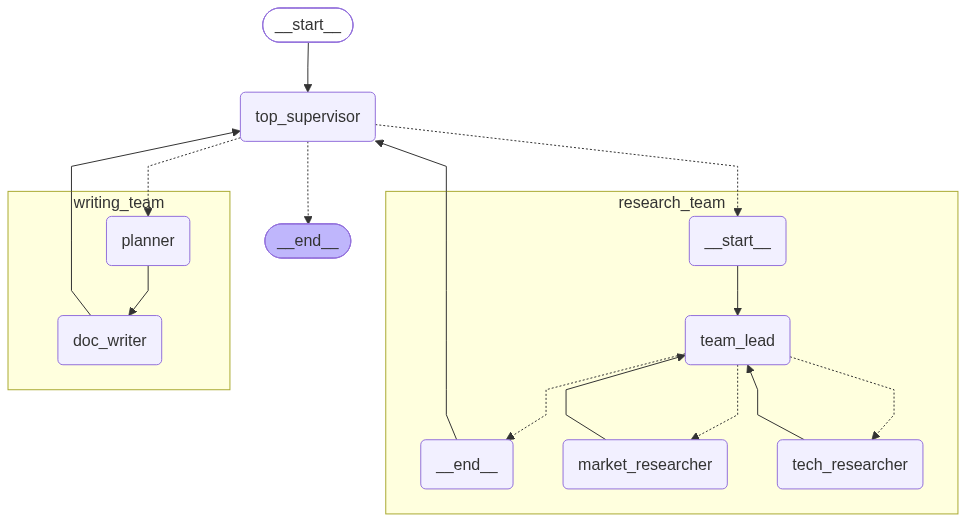

In [22]:
show_graph(hierarchical_app, xray=True)

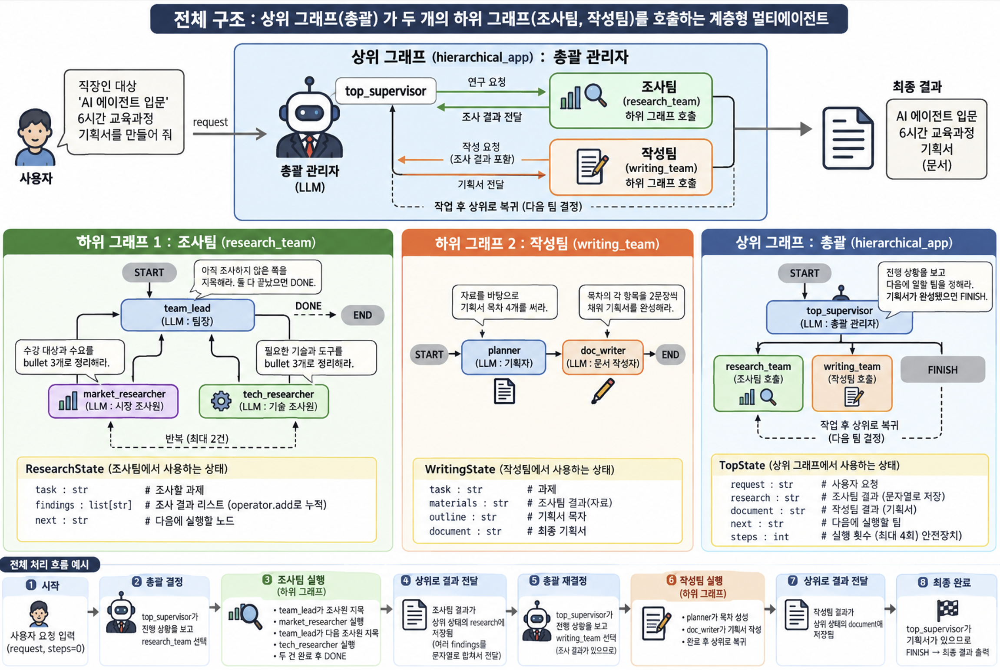

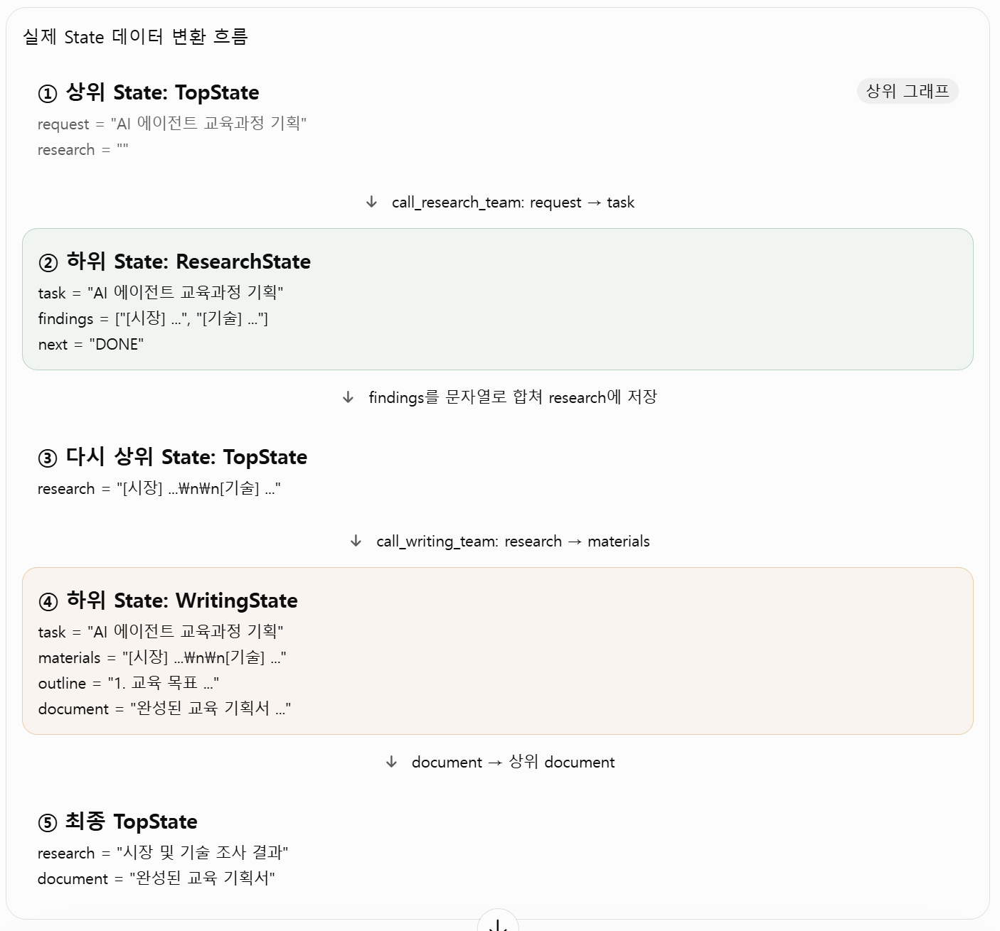

---
### 마무리 — 네 가지 패턴 비교

| | ① 순차형 | ② 슈퍼바이저형 | ③ 피드백 루프형 | ④ 계층형 |
|---|---|---|---|---|
| **다음 순서를 정하는 주체** | 코드 (`add_edge`) | 관리자 LLM | 조건 함수 (점수·횟수) | 총괄 LLM + 팀별 방식 |
| **핵심 LangGraph 기능** | `add_edge` | `add_conditional_edges` + 복귀 엣지 | 조건부 엣지로 만든 루프 | 서브그래프 |
| **실행 경로** | 항상 같음 | 요청마다 다름 | 품질에 따라 반복 횟수가 다름 | 팀 단위로 다름 |
| **LLM 호출 수** | 가장 적음 | 판단 호출이 추가됨 | 반복할수록 증가 | 가장 많음 |
| **예측 가능성** | 매우 높음 | 중간 | 중간 | 낮음 |
| **안전장치** | 필요 없음 | `MAX_STEPS` | `MAX_ROUNDS` | 단계별 상한 |

#### 어떤 패턴을 고를까?
```
업무 순서가 항상 같다?                 → ① 순차형부터 시작
요청마다 필요한 담당자가 다르다?       → ② 슈퍼바이저형
결과물 품질을 기준까지 올려야 한다?    → ③ 피드백 루프형
에이전트가 많고 업무 영역이 나뉜다?    → ④ 계층형
```

> 💡 **실무 팁**: 가장 단순한 패턴으로 시작하세요. 순차형으로 충분한데 슈퍼바이저형을 쓰면 LLM 호출과 예측하기 어려운 경로만 늘어납니다. 또 패턴은 **섞어 쓸 수 있습니다.** ④ 계층형 안에 ②와 ①이 들어 있었던 것처럼, ① 순차형 중간 단계에 ③ 피드백 루프를 넣는 식입니다.

#### LangChain과 LangGraph 역할 다시 보기
| 이 노트북에서 | LangChain | LangGraph |
|---|---|---|
| 각 에이전트의 글쓰기·판단 | ✅ `ask()`, `with_structured_output` | |
| 공유 메모장 | | ✅ `State` (TypedDict, 리듀서) |
| 순서·분기·반복·팀 구성 | | ✅ 엣지, 조건부 엣지, 서브그래프 |

---
#### 보너스 : LangChain 의 create_agent() 로 만든 에이전트를 LangGraph 의 노드로 넣는 법 

> **LangChain `create_agent()`로 전문가 에이전트를 만들고, LangGraph로 엮어 하나의 큰 에이전트로 만든다.**

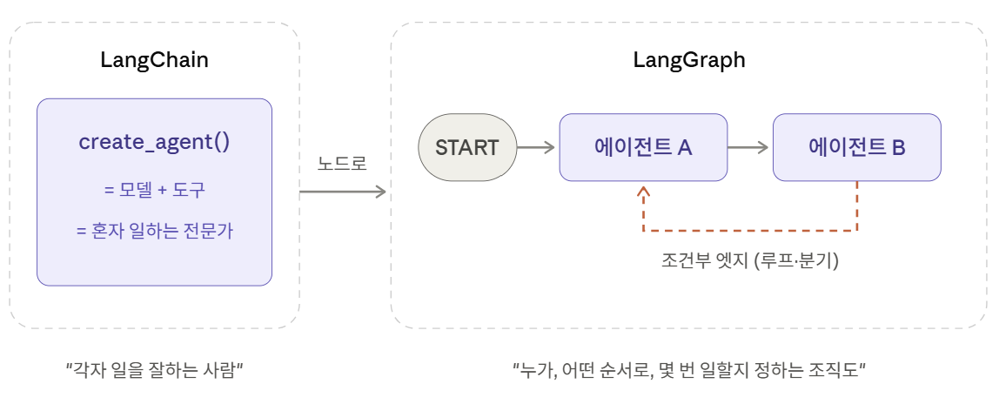

`create_agent()`가 만든 에이전트는 **`{"messages": [...]}`를 받고 `{"messages": [...]}`를 돌려주는** 작은 그래프입니다.
반면 우리가 설계할 큰 그래프의 State는 `weather`, `plan`, `budget`처럼 **업무에 맞는 칸**으로 되어 있습니다.

그래서 둘 사이에 **통역사(wrapper) 함수**를 둡니다.
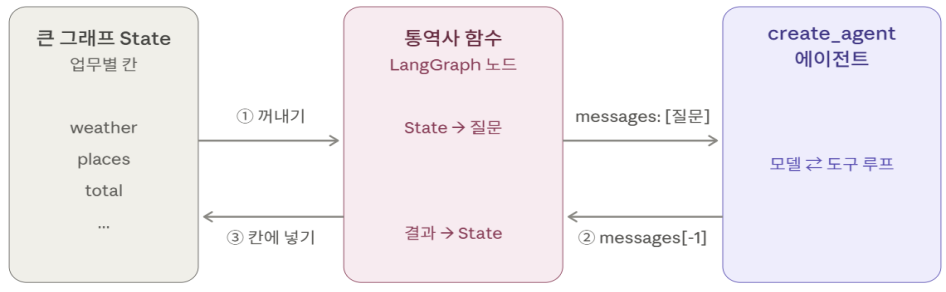

```python
def weather_node(state):                                         # 통역사 함수 = LangGraph 노드
    result = weather_agent.invoke({"messages": [("user", f"{state['request']} 날씨 알려줘")]})  # ① ②
    return {"weather": result["messages"][-1].text}               # ③
```

**장점**
- 각 에이전트는 **자기 일에 필요한 질문만** 받습니다. 다른 에이전트의 도구 호출 기록이 섞이지 않아 헷갈리지 않습니다.
- 에이전트마다 **모델·도구·미들웨어를 다르게** 줄 수 있습니다. (gemini 에이전트 + gpt 에이전트 혼합)
- 결과를 State의 **이름 있는 칸**에 넣으니, 다음 노드와 조건부 엣지가 쓰기 쉽습니다.

---
### 예제 ① 🌤️ 주말 나들이 플래너 — 순차 + 피드백 루프

#### 시나리오
"이번 토요일 서울에서 친구랑 둘이 놀 계획 짜 줘. 예산은 둘이 합쳐 8만 원."

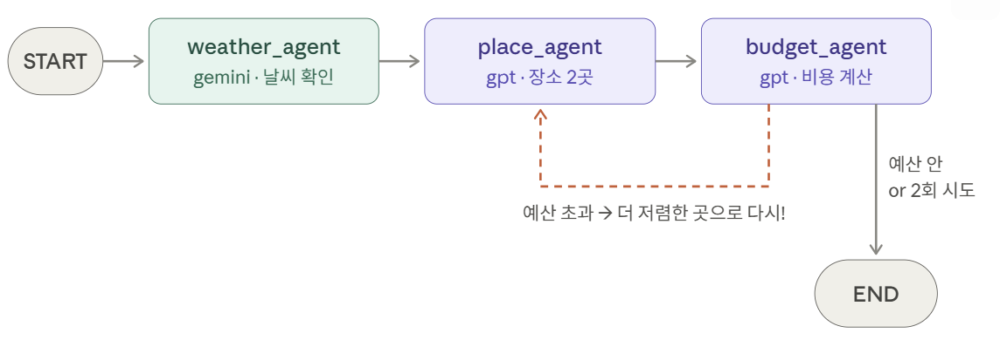

| 에이전트 | 모델 | 도구 | 하는 일 |
|---|---|---|---|
| `weather_agent` | gemini | `get_weather` (가끔 실패 ⚠️) | 토요일 날씨 확인 |
| `place_agent` | gpt | `search_places` | 날씨에 맞는 장소 2곳 고르기 |
| `budget_agent` | gpt | `get_price` | 비용 계산 후 **구조화 결과**(총액·예산 안인지) 반환 |

#### 포인트
- `budget_agent`는 `response_format=ToolStrategy(Budget)`로 **정해진 형식(파이썬 객체)**을 돌려줍니다. 총액이 숫자(`int`)로 오니까, 예산 비교는 **코드가 확실하게** 하고(`total <= limit`) 그 결과로 조건부 엣지가 분기합니다.
- `get_weather`는 일부러 가끔 `ToolException`을 내고, `ToolRetryMiddleware`가 자동으로 다시 시도합니다.

In [23]:
import random
from typing import TypedDict
from pydantic import BaseModel, Field
from langchain.agents import create_agent                                          # [LangChain]
from langchain.agents.middleware import ModelCallLimitMiddleware, ToolRetryMiddleware
from langchain.agents.structured_output import ToolStrategy
from langchain_core.tools import tool, ToolException

# ── 수업용 가상 데이터 ──────────────────────────────
WEATHER = {"토요일": {"sky": "비", "temp": 14, "rain_prob": 80}}
PLACES = [
    {"name": "국립중앙박물관", "type": "실내", "area": "용산"},
    {"name": "코엑스 아쿠아리움", "type": "실내", "area": "강남"},
    {"name": "방탈출 카페",      "type": "실내", "area": "홍대"},
    {"name": "한강 자전거",      "type": "실외", "area": "여의도"},
    {"name": "북한산 둘레길",    "type": "실외", "area": "은평"},
]
PRICES = {"국립중앙박물관": 0, "코엑스 아쿠아리움": 33000, "방탈출 카페": 22000,
          "한강 자전거": 5000, "북한산 둘레길": 0}
MEAL_PER_PERSON = 15000      # 1인 식사비 (고정)


# ── [LangChain] 도구 ────────────────────────────────
@tool
def get_weather(day: str) -> dict:
    "요일(예: 토요일)의 서울 날씨를 조회한다."
    if random.random() < 0.3:
        raise ToolException("기상청 서버 응답 지연")          # 실패는 '예외'로 → 재시도 미들웨어가 동작
    return WEATHER.get(day, {"sky": "맑음", "temp": 20, "rain_prob": 10})


@tool
def search_places(place_type: str) -> list[dict]:
    "장소 유형('실내' 또는 '실외')으로 서울의 놀거리를 찾는다."
    return [p for p in PLACES if p["type"] == place_type]


@tool
def get_price(place: str) -> int:
    "장소의 1인 입장료(원)를 조회한다."
    if place not in PRICES:
        raise ToolException(f"'{place}'의 가격 정보가 없습니다")
    return PRICES[place]


class Budget(BaseModel):                                               # budget_agent 의 결과 형식
    total: int = Field(description="식사비를 포함한 전체 비용(원)")
    detail: str = Field(description="항목별 계산 내역 한두 줄")


# ── [LangChain] 전문가 에이전트 3명 ───────────────────
weather_agent = create_agent(
    model=gemini,
    tools=[get_weather],
    system_prompt="너는 기상 캐스터다. 반드시 get_weather 도구로 확인하고, 날씨와 실내/실외 활동 추천 여부를 한 문장으로 답한다.",
    middleware=[ToolRetryMiddleware(max_retries=3, initial_delay=0.3),
                ModelCallLimitMiddleware(run_limit=4, exit_behavior="end")],
    name="weather_agent",
)

place_agent = create_agent(
    model=gpt,
    tools=[search_places],
    system_prompt="너는 서울 나들이 가이드다. search_places 도구로 찾은 장소 중에서만 2곳을 골라 "
                  "'장소1, 장소2' 형식과 고른 이유 한 줄로 답한다.",
    middleware=[ModelCallLimitMiddleware(run_limit=4, exit_behavior="end")],
    name="place_agent",
)

budget_agent = create_agent(
    model=gpt,
    tools=[get_price],
    system_prompt=f"너는 꼼꼼한 회계 담당이다. 각 장소의 1인 가격을 get_price 도구로 조회하고, "
                  f"1인 식사비 {MEAL_PER_PERSON}원을 더해 인원수만큼 곱한 총액을 계산한다.",
    response_format=ToolStrategy(Budget),                              # 결과를 Budget 객체로 받기
    middleware=[ModelCallLimitMiddleware(run_limit=6, exit_behavior="end")],
    name="budget_agent",
)

### 큰 그래프 설계: State와 통역사 함수

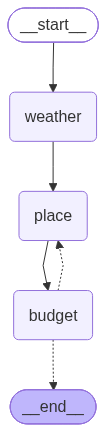

In [24]:
from langgraph.graph import StateGraph, START, END                    # [LangGraph]

MAX_TRIES = 2


class TripState(TypedDict):
    request: str        # 사용자 요청
    people: int         # 인원
    limit: int          # 예산(원)
    weather: str        # weather_agent 결과
    places: str         # place_agent 결과
    total: int          # budget_agent 결과 (구조화)
    within_budget: bool
    detail: str
    tries: int          # 장소 계획 횟수 (루프 제한용)


# ── [LangGraph] 통역사 함수 = 노드 ─────────────────────
def weather_node(state: TripState) -> dict:
    result = weather_agent.invoke({"messages": [("user", f"요청: {state['request']}\n토요일 날씨를 알려줘.")]})
    answer = result["messages"][-1].text
    print(f"🌤️ weather_agent : {answer}")
    return {"weather": answer}


def place_node(state: TripState) -> dict:
    tries = state.get("tries", 0) + 1
    ask = f"요청: {state['request']}\n날씨: {state['weather']}\n장소 2곳을 골라줘."
    if state.get("detail"):                                               # 두 번째부터는 예산 피드백 포함
        ask += f"\n⚠️ 이전 계획 '{state['places']}'은(는) 예산 초과였다({state['detail']}). 더 저렴한 곳으로 바꿔라."
    result = place_agent.invoke({"messages": [("user", ask)]})
    answer = result["messages"][-1].text
    print(f"📍 place_agent  : ({tries}회차) {answer}")
    return {"places": answer, "tries": tries}


def budget_node(state: TripState) -> dict:
    ask = f"장소: {state['places']}\n인원: {state['people']}명\n예산: {state['limit']}원"
    result = budget_agent.invoke({"messages": [("user", ask)]})
    b: Budget = result["structured_response"]                            # ToolStrategy 결과 = 파이썬 객체
    within = b.total <= state["limit"]                                    # 예산 비교는 LLM 이 아니라 코드로!
    print(f"💰 budget_agent : {b.total:,}원 / 예산 {'안 ✅' if within else '초과 ❌'} — {b.detail}")
    return {"total": b.total, "within_budget": within, "detail": b.detail}


# ── [LangGraph] 분기 함수 ────────────────────────────
def check_budget(state: TripState) -> str:
    if state["within_budget"] or state["tries"] >= MAX_TRIES:
        return END
    return "place"                                                        # 예산 초과 → 장소 다시 고르기


builder = StateGraph(TripState)
builder.add_node("weather", weather_node)
builder.add_node("place", place_node)
builder.add_node("budget", budget_node)

builder.add_edge(START, "weather")
builder.add_edge("weather", "place")
builder.add_edge("place", "budget")
builder.add_conditional_edges("budget", check_budget, ["place", END])

trip_app = builder.compile()
show_graph(trip_app)

In [25]:
state = trip_app.invoke({
    "request": "이번 토요일 서울에서 친구랑 둘이 놀 계획 짜 줘",
    "people": 2,
    "limit": 80000,
})

print("\n" + "=" * 60)
print(f"📋 최종 계획 ({state['tries']}회차)")
print(f"  날씨 : {state['weather']}")
print(f"  장소 : {state['places']}")
print(f"  비용 : {state['total']:,}원 / 예산 {state['limit']:,}원 → {'OK' if state['within_budget'] else '초과(최대 시도 도달)'}")

🌤️ weather_agent : 이번 토요일 서울은 비가 내리고 기온은 14도로 예상되니, 실내 데이트나 활동을 추천합니다!
📍 place_agent  : (1회차) 국립중앙박물관, 코엑스 아쿠아리움 - 두 곳 모두 실내에서 즐길 수 있는 문화 체험과 재미있는 활동을 제공하여 비 오는 날에 적합합니다.
💰 budget_agent : 78,000원 / 예산 안 ✅ — 국립중앙박물관 입장료: 0원, 코엑스 아쿠아리움 입장료: 33000원, 식사비: 30000원 (15000원 x 2명)

📋 최종 계획 (1회차)
  날씨 : 이번 토요일 서울은 비가 내리고 기온은 14도로 예상되니, 실내 데이트나 활동을 추천합니다!
  장소 : 국립중앙박물관, 코엑스 아쿠아리움 - 두 곳 모두 실내에서 즐길 수 있는 문화 체험과 재미있는 활동을 제공하여 비 오는 날에 적합합니다.
  비용 : 78,000원 / 예산 80,000원 → OK


**📝 정리** — budget_agent가 78,000원 "예산 안"이라고 했지만 지시대로면 (0 + 33,000 + 15,000) × 2명 = **96,000원**으로 예산 초과다. 비교(`<=`)는 코드가 했어도 **총액을 LLM이 계산**해 안전장치가 통하지 않았다. 합계는 코드에서 계산해야 한다.

> 💡 **실험해 보기**
> - `WEATHER["토요일"]["sky"]`를 `"맑음"`으로 바꾸면 `place_agent`가 실외 장소를 고르는지 확인해 보세요.
> - `limit`를 `40000`으로 줄이면 루프가 최대 횟수(`MAX_TRIES`)까지 돌고 멈추는 것을 볼 수 있습니다.

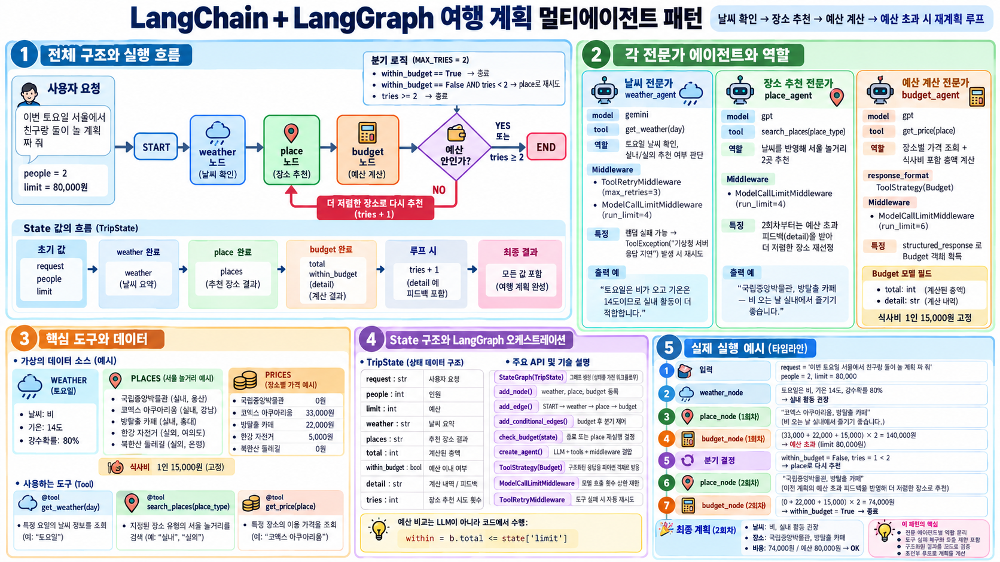

<hr style="height:5px; background : linear-gradient(to right, brown, yellow)">

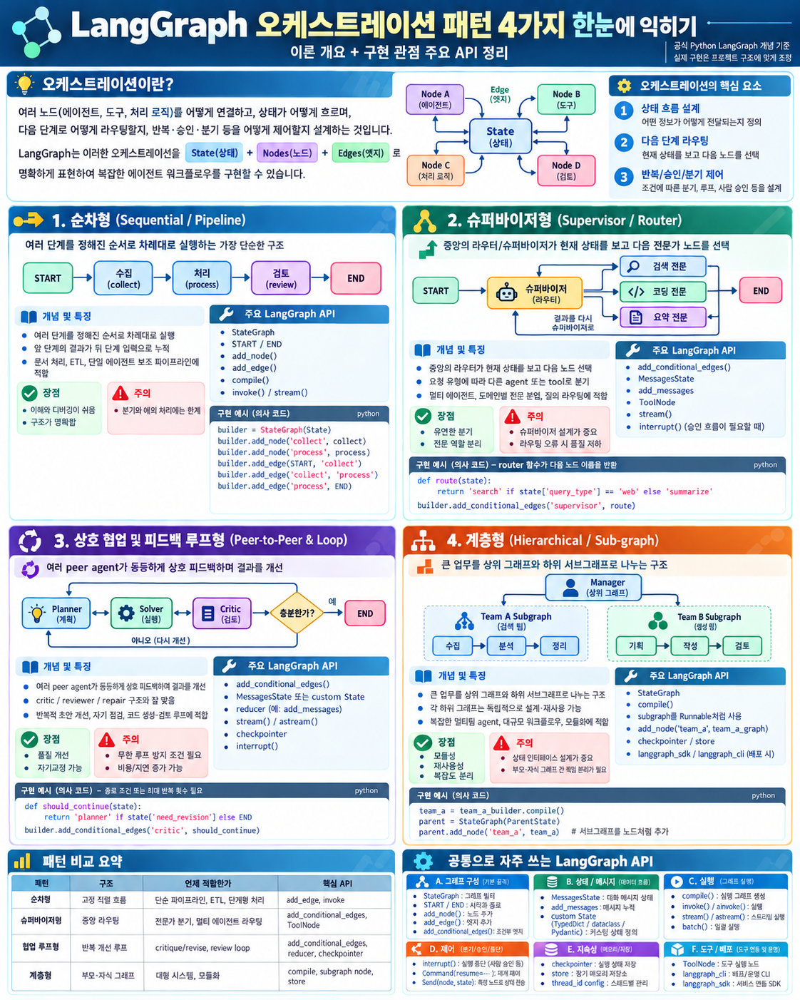

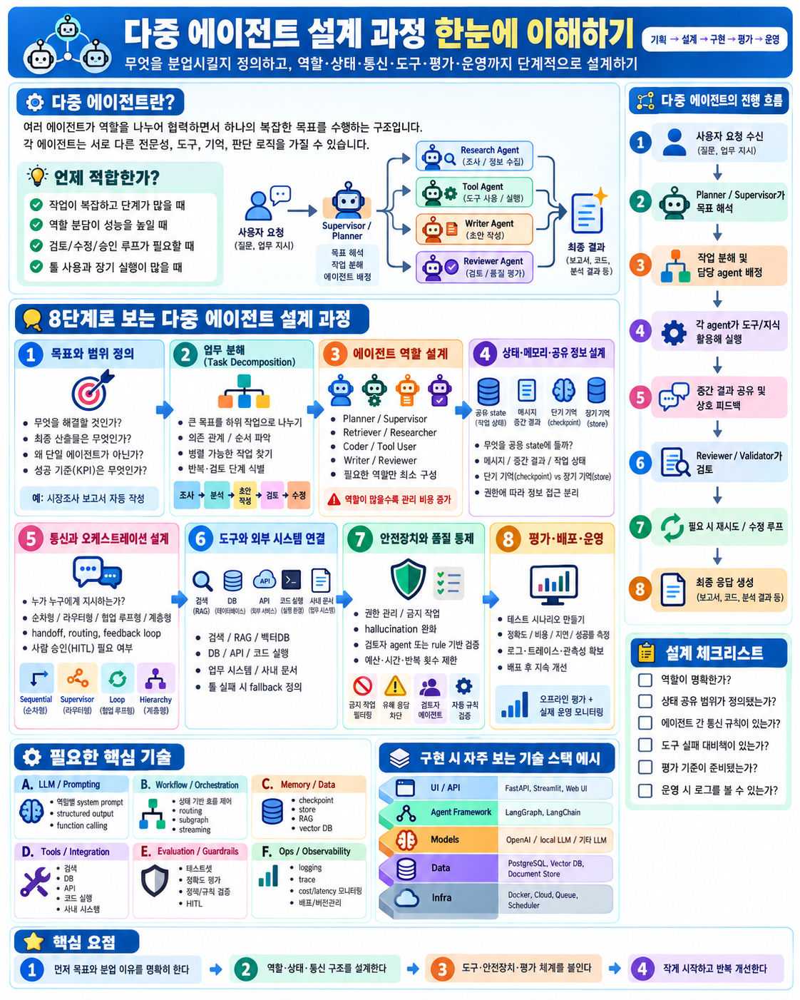

### 멀티에이전트 개발을 위한 핵심 기술 총정리

- 멀티에이전트(Multi-Agent) 시스템을 개발하려면 LLM을 여러 개 호출하는 방법뿐 아니라, 에이전트 간 작업 분담, 실행 제어, 데이터 공유, 기억 관리, 도구 사용, 오류 복구까지 이해해야 합니다.

- 앞서 학습한 LangChain·LangGraph를 기준으로, 실제 개발에 필요한 기술을 10개 영역으로 구분하겠습니다.

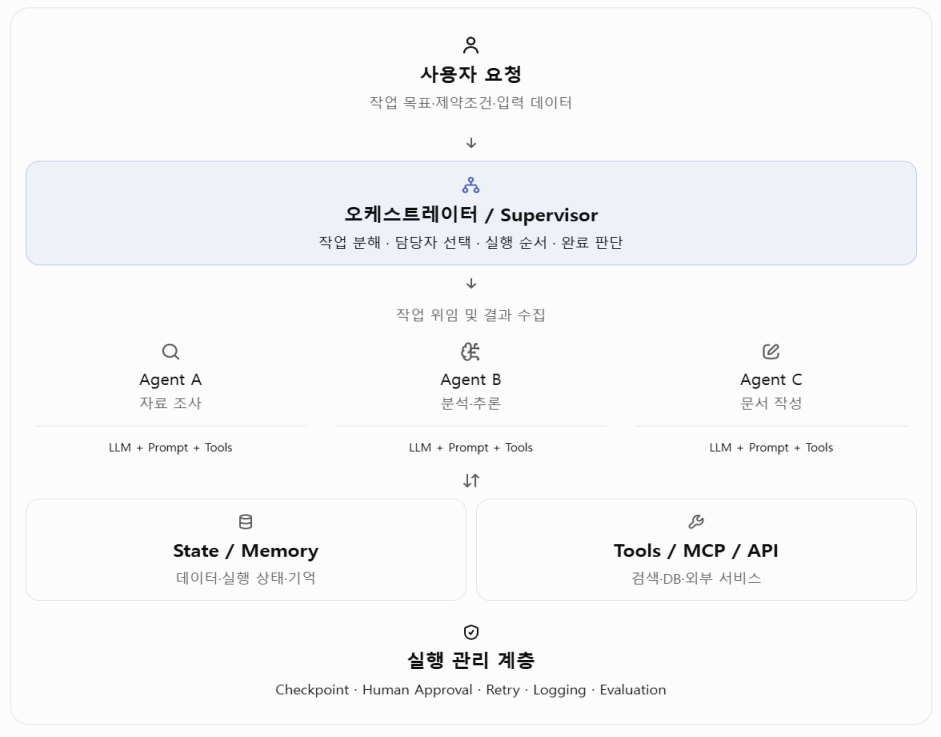

반드시 알아야 할 10개 기술 영역

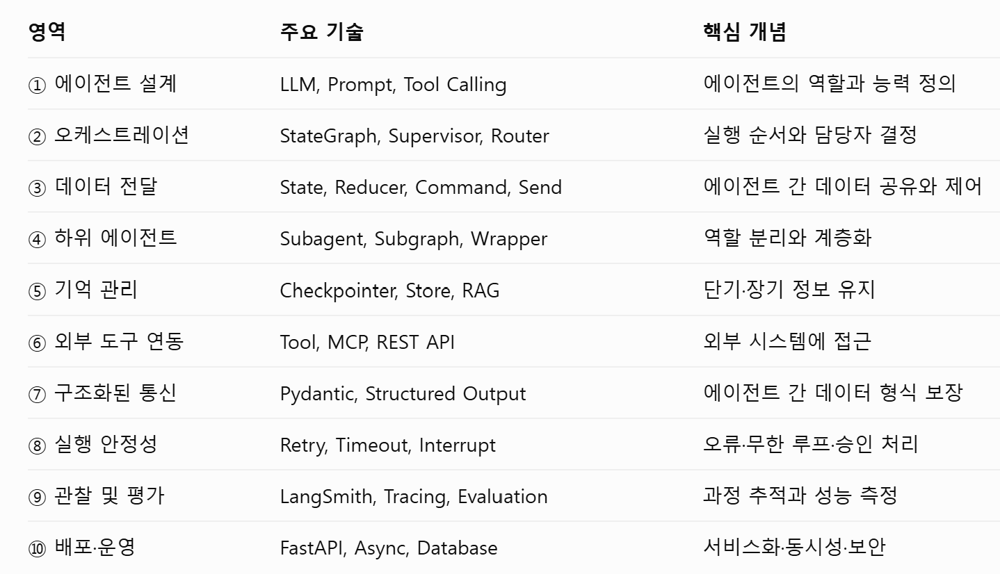

LangGraph 데이터 전달 기술

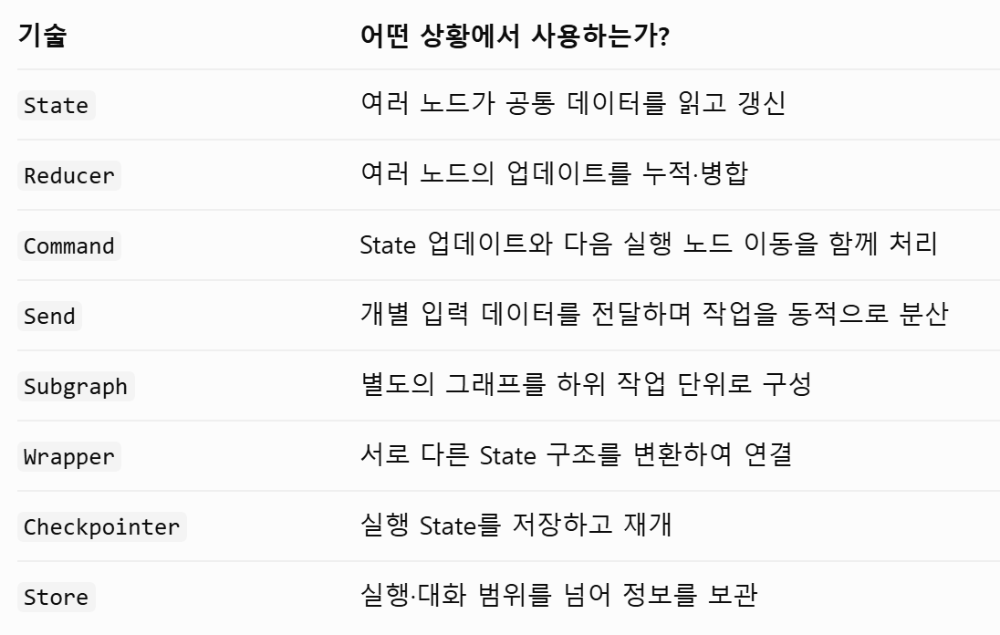

기억 관리와 데이터 저장 기술
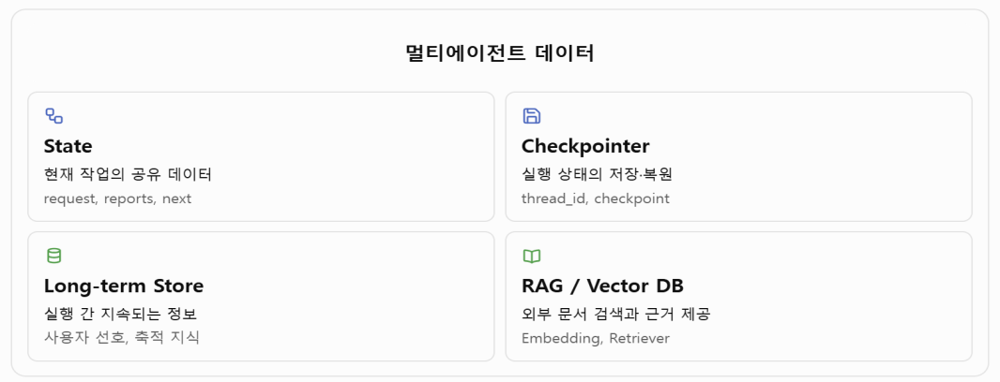

에이전트 협업 방식

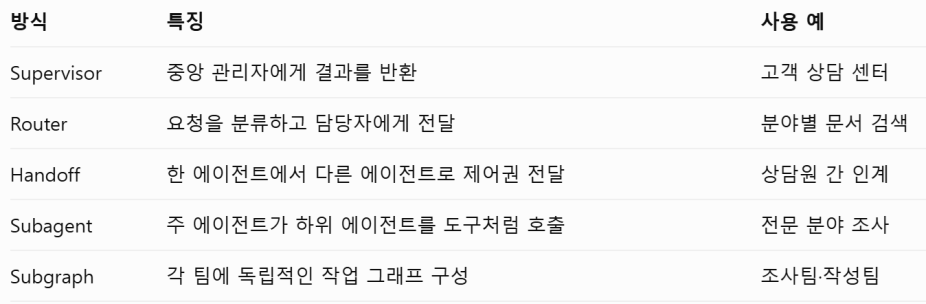

### LangSmith : **AI 에이전트의 블랙박스(운행 기록 장치)**

에이전트가 실행될 때 어떤 단계를 거쳤는지, LLM에 무엇을 묻고 무엇을 답받았는지, 시간과 비용이 얼마나 들었는지를 모두 기록해서 화면으로 보여 줍니다. 그래서 에이전트가 이상한 답을 하면, 어느 단계에서 왜 그랬는지 찾아낼 수 있습니다.

In [26]:
%pip install -U langsmith 

   ---------------------------------------- 0.0/940.8 kB ? eta -:--:--
   --------------------------------- ------ 786.4/940.8 kB 3.7 MB/s eta 0:00:01
   ---------------------------------------- 940.8/940.8 kB 3.6 MB/s  0:00:00
  Attempting uninstall: langsmith
    Found existing installation: langsmith 0.14.16
    Uninstalling langsmith-0.14.16:
      Successfully uninstalled langsmith-0.14.16
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


```
setx LANGSMITH_TRACING "true"
setx LANGSMITH_API_KEY "lsv2_..."
setx LANGSMITH_PROJECT "exam14"
```

**📝 정리** — 실제 `LANGSMITH_API_KEY` 값은 노트북·코드에 쓰지 않고 환경변수로만 둔다. 트레이스에는 프롬프트와 답변 원문이 저장되므로 개인정보가 들어가는 실행은 끄고 돌린다.

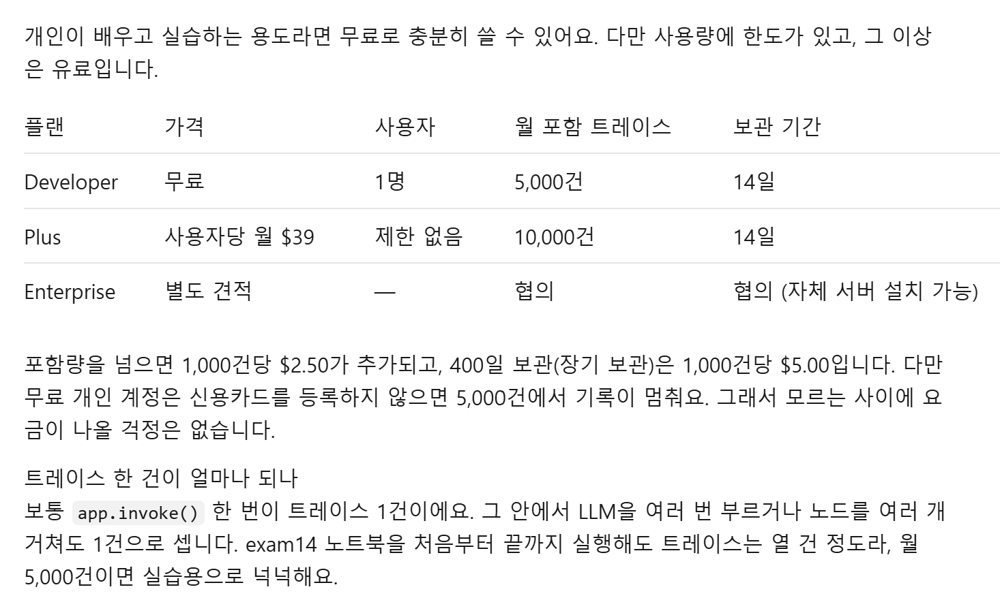

### LangChain으로 만들고, LangGraph로 연결하고, LangSmith로 들여다본다.

#### LangSmith 기록을 잠시 끄는 방법은 상황에 따라 2가지입니다.

1. 특정 실행만 잠깐 끄기 (가장 간편)

tracing_context(enabled=False) 블록 안에서 실행한 것만 기록되지 않습니다. 커널을 재시작할 필요가 없습니다.

```
from langsmith import tracing_context

with tracing_context(enabled=False):          # 이 블록 안의 실행은 기록 안 됨
    result = poem_app.invoke({"word": "둘리"})

poem_app.invoke({"word": "또치"})              # 블록 밖은 다시 기록됨
```

2. 명령 프롬프트에서 아래를 실행하고 VS Code를 재시작합니다. 다시 켤 때는 "true"로 설정하면 됩니다.

`setx LANGSMITH_TRACING "false"`

## 🔁 복습 질문

<details>
<summary>1. 슈퍼바이저형에 <code>MAX_STEPS</code>가 없었다면?</summary>

FINISH를 고르지 않아 `recursion_limit`에 걸려 예외로 끝나고 답변도 만들어지지 않았을 것이다.
</details>

<details>
<summary>2. 계층형에서 팀을 wrapper 함수로 감싼 이유는?</summary>

팀마다 State 키가 달라서다. wrapper가 상위 ↔ 하위 State를 바꿔 준다.
</details>

<details>
<summary>3. budget_node가 틀린 총액을 통과시킨 이유는?</summary>

비교할 숫자를 LLM이 만들었기 때문이다. 가격은 도구로 받고 합계는 코드로 계산한다.
</details>
